# 03 · Simple and Multiple Linear Regression

**Syllabus:** Unit 1 (Simple Linear Regression) and Unit 2 (Multiple Linear Regression: estimation).

**Report items:** *Simple Linear Regression*, *Multiple Linear Regression*.

Assumption tests and diagnostics are in notebook 04.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
%matplotlib inline

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed" / "bengaluru_clean.csv"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

## 2. Modelling dataset

- **Target:** `PM2.5`
- **Predictors:** 8 co-pollutants. Benzene and Toluene are left out because they have long gaps and near-zero correlation with PM2.5.
- Only **complete rows** are used, so no data is invented.
- Column names like `PM2.5` break formulas, so they are renamed (`PM2.5` → `PM25`).

**Train/test split:** chronological 80/20. A time series must not be shuffled, or the model would see the future. Inference (tests, CIs, ANOVA) uses the training set; the test set is kept for honest evaluation. Every later notebook uses this same `SPLIT_DATE`.

In [2]:
PREDICTORS = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]

df = pd.read_csv(DATA, parse_dates=["Date"])
df = df.rename(columns={"PM2.5": "PM25"})
model_df = df.dropna(subset=["PM25"] + PREDICTORS).reset_index(drop=True)

SPLIT_DATE = model_df["Date"].quantile(0.8).normalize()
train = model_df[model_df["Date"] < SPLIT_DATE].copy()
test = model_df[model_df["Date"] >= SPLIT_DATE].copy()

print("Complete rows:", len(model_df))
print("SPLIT_DATE:", SPLIT_DATE.date())
print(f"Train: {len(train)} rows ({train.Date.min().date()} -> {train.Date.max().date()})")
print(f"Test : {len(test)} rows ({test.Date.min().date()} -> {test.Date.max().date()})")

Complete rows: 1478
SPLIT_DATE: 2019-09-09
Train: 1181 rows (2015-11-07 -> 2019-09-08)
Test : 297 rows (2019-09-09 -> 2020-07-01)


# Part A: Simple Linear Regression

Model: $PM2.5_i = \beta_0 + \beta_1 \cdot PM10_i + \varepsilon_i$

PM10 is chosen as the single predictor because it has the highest correlation with PM2.5 (EDA) and both are particulate matter from similar sources.

## 3. Least-squares estimation by hand

$$\hat\beta_1 = \frac{S_{xy}}{S_{xx}} = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x$$

Computing it manually first shows what the library is doing.

In [3]:
x, y = train["PM10"].values, train["PM25"].values
n = len(x)
Sxx = np.sum((x - x.mean()) ** 2)
Sxy = np.sum((x - x.mean()) * (y - y.mean()))
b1 = Sxy / Sxx
b0 = y.mean() - b1 * x.mean()

resid = y - (b0 + b1 * x)
SSE = np.sum(resid ** 2)
MSE = SSE / (n - 2)                      # unbiased estimate of sigma^2
se_b1 = np.sqrt(MSE / Sxx)
se_b0 = np.sqrt(MSE * (1 / n + x.mean() ** 2 / Sxx))

print(f"b0 = {b0:.4f}  (SE {se_b0:.4f})")
print(f"b1 = {b1:.4f}  (SE {se_b1:.4f})")
print(f"sigma_hat = sqrt(MSE) = {np.sqrt(MSE):.3f}")

b0 = 10.9940  (SE 1.0682)
b1 = 0.2804  (SE 0.0108)
sigma_hat = sqrt(MSE) = 14.861


## 4. Same model with statsmodels

The estimates must match the manual calculation.

In [4]:
slr = smf.ols("PM25 ~ PM10", data=train).fit()
print(slr.summary())

                            OLS Regression Results                            
Dep. Variable:                   PM25   R-squared:                       0.362
Model:                            OLS   Adj. R-squared:                  0.362
Method:                 Least Squares   F-statistic:                     670.4
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          2.16e-117
Time:                        23:18:38   Log-Likelihood:                -4862.0
No. Observations:                1181   AIC:                             9728.
Df Residuals:                    1179   BIC:                             9738.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     10.9940      1.068     10.292      0.0

In [5]:
assert np.isclose(slr.params["PM10"], b1) and np.isclose(slr.params["Intercept"], b0)
print("Manual least-squares estimates match statsmodels.")

Manual least-squares estimates match statsmodels.


## 5. Hypothesis test and interval estimation of parameters

- $H_0: \beta_1 = 0$ (PM10 has no linear effect on PM2.5) vs $H_1: \beta_1 \ne 0$
- Test statistic $t = \hat\beta_1 / SE(\hat\beta_1) \sim t_{n-2}$
- 95% CI: $\hat\beta_1 \pm t_{0.025,\,n-2} \cdot SE(\hat\beta_1)$

In [6]:
t_crit = stats.t.ppf(0.975, df=n - 2)
t_b1 = b1 / se_b1
p_b1 = 2 * stats.t.sf(abs(t_b1), df=n - 2)
print(f"t = {t_b1:.3f}, p = {p_b1:.3e}, t_crit = {t_crit:.3f}")
print(f"Manual 95% CI for b1: [{b1 - t_crit*se_b1:.4f}, {b1 + t_crit*se_b1:.4f}]")

slr_coef = pd.DataFrame({
    "estimate": slr.params, "std_err": slr.bse, "t": slr.tvalues, "p_value": slr.pvalues,
    "ci_lower": slr.conf_int()[0], "ci_upper": slr.conf_int()[1],
})
slr_coef.to_csv(TAB / "slr_coefficients.csv")
slr_coef

t = 25.891, p = 2.161e-117, t_crit = 1.962
Manual 95% CI for b1: [0.2591, 0.3016]


,estimate,std_err,t,p_value,ci_lower,ci_upper
Intercept,10.9940,1.0682,10.2923,0.0000,8.8983,13.0898
PM10,0.2804,0.0108,25.8912,0.0000,0.2591,0.3016


## 6. ANOVA for regression

Splits the total variation: $SST = SSR + SSE$. $F = MSR / MSE$ tests $H_0: \beta_1 = 0$. In simple regression $F = t^2$.

In [7]:
SST = np.sum((y - y.mean()) ** 2)
SSR = SST - SSE
anova_slr = pd.DataFrame({
    "df": [1, n - 2, n - 1],
    "SS": [SSR, SSE, SST],
    "MS": [SSR / 1, SSE / (n - 2), np.nan],
}, index=["Regression", "Residual", "Total"])
anova_slr.loc["Regression", "F"] = anova_slr.loc["Regression", "MS"] / anova_slr.loc["Residual", "MS"]
anova_slr.loc["Regression", "p_value"] = stats.f.sf(anova_slr.loc["Regression", "F"], 1, n - 2)
anova_slr.to_csv(TAB / "slr_anova.csv")
print(f"F = {anova_slr.loc['Regression','F']:.3f}   t^2 = {t_b1**2:.3f}")
anova_slr

F = 670.355   t^2 = 670.355


,df,SS,MS,F,p_value
Regression,1,148057.3951,148057.3951,670.3551,0.0000
Residual,1179,260398.8223,220.8641,NaN,NaN
Total,1180,408456.2174,NaN,NaN,NaN


## 7. Coefficient of determination

$R^2 = SSR/SST$ is the share of PM2.5 variance explained by PM10. Adjusted $R^2 = 1 - \frac{SSE/(n-p-1)}{SST/(n-1)}$ penalises extra predictors.

In [8]:
r2 = SSR / SST
adj_r2 = 1 - (SSE / (n - 2)) / (SST / (n - 1))
print(f"R^2 = {r2:.4f}  (statsmodels {slr.rsquared:.4f})")
print(f"Adj R^2 = {adj_r2:.4f}  (statsmodels {slr.rsquared_adj:.4f})")
print(f"Correlation^2 = {np.corrcoef(x, y)[0,1]**2:.4f}  (equals R^2 in SLR)")

R^2 = 0.3625  (statsmodels 0.3625)
Adj R^2 = 0.3619  (statsmodels 0.3619)
Correlation^2 = 0.3625  (equals R^2 in SLR)


## 8. Prediction of a new observation

For a new day with PM10 = $x_0$:
- **Confidence interval** for the *mean* PM2.5 of all such days
- **Prediction interval** for *one* new day (wider, because it adds the day-to-day noise $\sigma^2$)

$$\hat y_0 \pm t_{0.025,n-2}\sqrt{MSE\left(1 + \frac1n + \frac{(x_0-\bar x)^2}{S_{xx}}\right)}$$

In [9]:
new = pd.DataFrame({"PM10": [50, 100, 150]})
pred = slr.get_prediction(new).summary_frame(alpha=0.05)
pred.insert(0, "PM10", new["PM10"])
pred = pred.rename(columns={"mean": "pred_PM25", "mean_ci_lower": "CI_low", "mean_ci_upper": "CI_high",
                            "obs_ci_lower": "PI_low", "obs_ci_upper": "PI_high"}).drop(columns="mean_se")
pred.to_csv(TAB / "slr_new_predictions.csv", index=False)
pred

,PM10,pred_PM25,CI_low,CI_high,PI_low,PI_high
0,50,25.0132,23.8094,26.2170,-4.1696,54.1960
1,100,39.0324,38.1587,39.9060,9.8613,68.2034
2,150,53.0515,51.5236,54.5795,23.8536,82.2495


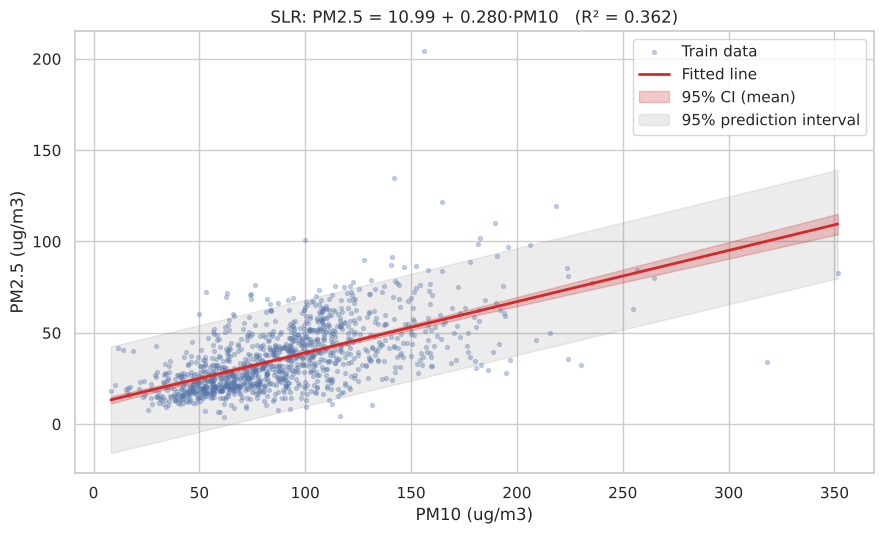

In [10]:
grid = pd.DataFrame({"PM10": np.linspace(train.PM10.min(), train.PM10.max(), 200)})
band = slr.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(train.PM10, train.PM25, s=8, alpha=0.3, label="Train data")
ax.plot(grid.PM10, band["mean"], color="#d62828", lw=2, label="Fitted line")
ax.fill_between(grid.PM10, band.mean_ci_lower, band.mean_ci_upper, color="#d62828", alpha=0.25, label="95% CI (mean)")
ax.fill_between(grid.PM10, band.obs_ci_lower, band.obs_ci_upper, color="grey", alpha=0.15, label="95% prediction interval")
ax.set_xlabel("PM10 (ug/m3)"); ax.set_ylabel("PM2.5 (ug/m3)")
ax.set_title(f"SLR: PM2.5 = {b0:.2f} + {b1:.3f}·PM10   (R² = {r2:.3f})")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "06_slr_fit.png", dpi=150); plt.show()

# Part B: Multiple Linear Regression

Matrix form: $\mathbf y = \mathbf X\boldsymbol\beta + \boldsymbol\varepsilon$, with OLS estimate $\hat{\boldsymbol\beta} = (\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$.

**Gauss-Markov theorem:** if errors have mean 0, constant variance and are uncorrelated, OLS is the **Best Linear Unbiased Estimator (BLUE)**: no other linear unbiased estimator has smaller variance. Notebook 04 checks whether these conditions hold here.

## 9. Model 1: pollutants only

In [11]:
formula_1 = "PM25 ~ " + " + ".join(PREDICTORS)
mlr1 = smf.ols(formula_1, data=train).fit()
print(mlr1.summary())

                            OLS Regression Results                            
Dep. Variable:                   PM25   R-squared:                       0.532
Model:                            OLS   Adj. R-squared:                  0.528
Method:                 Least Squares   F-statistic:                     166.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          5.16e-187
Time:                        23:18:39   Log-Likelihood:                -4680.0
No. Observations:                1181   AIC:                             9378.
Df Residuals:                    1172   BIC:                             9424.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -6.3472      1.627     -3.901      0.0

## 10. OLS in matrix form (verification)

In [12]:
X = sm.add_constant(train[PREDICTORS]).values
beta_hat = np.linalg.solve(X.T @ X, X.T @ train["PM25"].values)
check = pd.DataFrame({"matrix_formula": beta_hat, "statsmodels": mlr1.params.values}, index=mlr1.params.index)
check

,matrix_formula,statsmodels
Intercept,-6.3472,-6.3472
PM10,0.2046,0.2046
NO,-0.4076,-0.4076
NO2,0.3226,0.3226
NOx,0.3498,0.3498
NH3,0.1157,0.1157
CO,-0.4848,-0.4848
SO2,0.8111,0.8111
O3,0.1580,0.1580


## 11. Model 2: pollutants + season

EDA showed strong seasonality. `C(Season)` creates dummy variables with Winter as the reference level.

*Lockdown is not used:* the lockdown days (Mar-Jul 2020) all fall in the test period, so the training data has no lockdown days and its coefficient cannot be estimated.

In [13]:
formula_2 = formula_1 + " + C(Season, Treatment('Winter'))"
mlr2 = smf.ols(formula_2, data=train).fit()
print(mlr2.summary())

                            OLS Regression Results                            
Dep. Variable:                   PM25   R-squared:                       0.567
Model:                            OLS   Adj. R-squared:                  0.563
Method:                 Least Squares   F-statistic:                     139.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          1.37e-203
Time:                        23:18:39   Log-Likelihood:                -4633.5
No. Observations:                1181   AIC:                             9291.
Df Residuals:                    1169   BIC:                             9352.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

## 12. Coefficient table and interpretation

Each slope is the expected change in PM2.5 (µg/m³) for a 1-unit rise in that predictor, **holding all other predictors constant**.

In [14]:
mlr_coef = pd.DataFrame({
    "estimate": mlr2.params, "std_err": mlr2.bse, "t": mlr2.tvalues, "p_value": mlr2.pvalues,
    "ci_lower": mlr2.conf_int()[0], "ci_upper": mlr2.conf_int()[1],
})
mlr_coef["significant_5%"] = mlr_coef["p_value"] < 0.05
mlr_coef.to_csv(TAB / "mlr_coefficients.csv")
mlr_coef.round(4)

,estimate,std_err,t,p_value,ci_lower,ci_upper,significant_5%
Intercept,6.7252,2.3554,2.8552,0.0044,2.1039,11.3464,True
"C(Season, Treatment('Winter'))[T.Monsoon]",-10.9253,1.2624,-8.6543,0.0000,-13.4022,-8.4485,True
"C(Season, Treatment('Winter'))[T.Post-monsoon]",-2.3048,1.2509,-1.8425,0.0657,-4.7590,0.1495,False
"C(Season, Treatment('Winter'))[T.Summer]",-2.3434,1.1738,-1.9965,0.0461,-4.6464,-0.0405,True
PM10,0.1800,0.0110,16.3894,0.0000,0.1584,0.2015,True
NO,-0.2743,0.0691,-3.9669,0.0001,-0.4099,-0.1386,True
NO2,0.1637,0.0446,3.6681,0.0003,0.0762,0.2513,True
NOx,0.3039,0.0282,10.7842,0.0000,0.2486,0.3592,True
NH3,0.1230,0.0295,4.1739,0.0000,0.0652,0.1808,True
CO,-0.5981,0.4063,-1.4721,0.1413,-1.3952,0.1991,False


## 13. ANOVA tables

- **Overall F-test:** $H_0$: all slopes = 0.
- **Type II ANOVA:** contribution of each term given the others.
- **Partial F-test (nested models):** does adding season significantly improve Model 1?

In [15]:
print(f"Overall F-test (Model 2): F = {mlr2.fvalue:.2f}, p = {mlr2.f_pvalue:.3e}")
anova_terms = sm.stats.anova_lm(mlr2, typ=2)
anova_terms.to_csv(TAB / "mlr_anova_type2.csv")
anova_terms

Overall F-test (Model 2): F = 139.18, p = 1.373e-203


,sum_sq,df,F,PR(>F)
"C(Season, Treatment('Winter'))",14493.3496,3.0000,31.9352,0.0000
PM10,40635.4447,1.0000,268.6132,0.0000
NO,2380.5710,1.0000,15.7363,0.0001
NO2,2035.4375,1.0000,13.4549,0.0003
NOx,17593.6197,1.0000,116.2994,0.0000
NH3,2635.4885,1.0000,17.4214,0.0000
CO,327.8121,1.0000,2.1669,0.1413
SO2,3061.8952,1.0000,20.2401,0.0000
O3,2395.0336,1.0000,15.8319,0.0001
Residual,176844.7628,1169.0000,NaN,NaN


In [16]:
partial_f = sm.stats.anova_lm(mlr1, mlr2)
partial_f.index = ["Model 1 (pollutants)", "Model 2 (+ season)"]
partial_f.to_csv(TAB / "mlr_partial_f_test.csv")
partial_f

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
Model 1 (pollutants),1172.0000,191338.1125,0.0000,NaN,NaN,NaN
Model 2 (+ season),1169.0000,176844.7628,3.0000,14493.3496,31.9352,0.0000


## 14. Comparing SLR and MLR

In-sample fit on train, and out-of-sample accuracy on the held-out test period.

In [17]:
def evaluate(name, model):
    pred = model.predict(test)
    return {
        "model": name, "n_params": int(model.df_model) + 1,
        "R2_train": model.rsquared, "AdjR2_train": model.rsquared_adj,
        "AIC": model.aic, "BIC": model.bic,
        "RMSE_test": np.sqrt(mean_squared_error(test["PM25"], pred)),
        "MAE_test": mean_absolute_error(test["PM25"], pred),
        "R2_test": r2_score(test["PM25"], pred),
    }

comparison = pd.DataFrame([
    evaluate("SLR: PM10", slr),
    evaluate("MLR 1: pollutants", mlr1),
    evaluate("MLR 2: + season", mlr2),
]).set_index("model")
comparison.to_csv(TAB / "regression_comparison.csv")
comparison.round(3)

,n_params,R2_train,AdjR2_train,AIC,BIC,RMSE_test,MAE_test,R2_test
model,,,,,,,,
SLR: PM10,2,0.3620,0.3620,9728.0350,9738.1830,8.0800,6.0780,0.6300
MLR 1: pollutants,9,0.5320,0.5280,9378.0840,9423.7510,7.0190,5.4810,0.7210
MLR 2: + season,12,0.5670,0.5630,9291.0560,9351.9460,8.5710,6.8620,0.5840


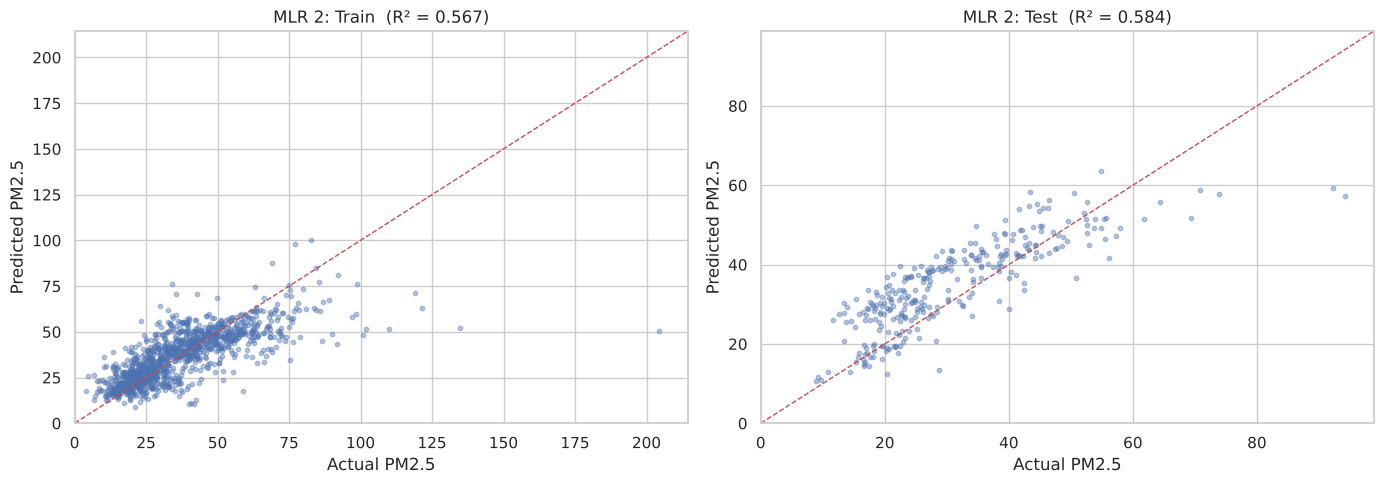

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, model, data) in zip(axes, [("Train", mlr2, train), ("Test", mlr2, test)]):
    p = model.predict(data)
    ax.scatter(data["PM25"], p, s=10, alpha=0.4)
    lim = [0, max(data["PM25"].max(), p.max()) * 1.05]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Actual PM2.5"); ax.set_ylabel("Predicted PM2.5")
    ax.set_title(f"MLR 2: {name}  (R² = {r2_score(data['PM25'], p):.3f})")
fig.tight_layout(); fig.savefig(FIG / "07_mlr_actual_vs_pred.png", dpi=150); plt.show()

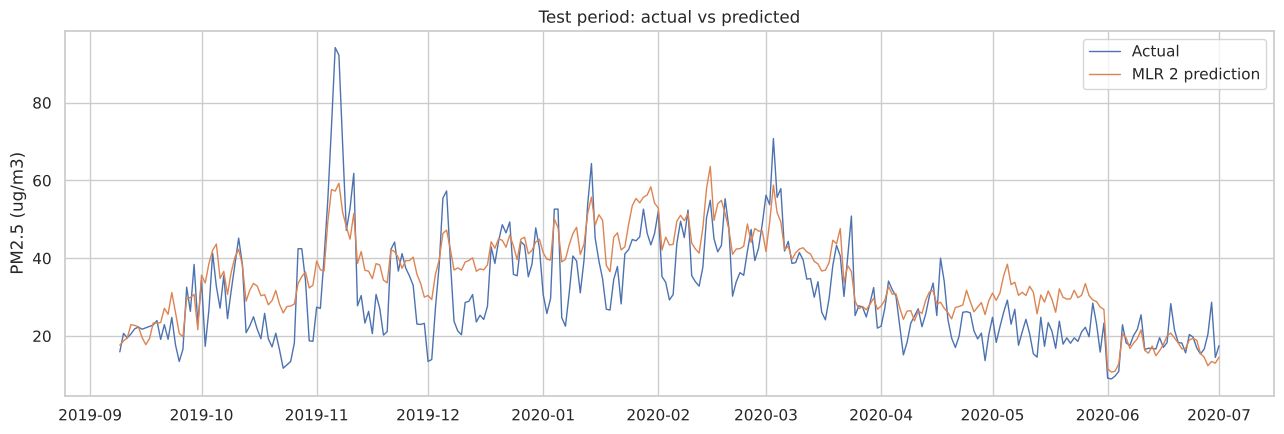

In [19]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(test["Date"], test["PM25"], lw=1, label="Actual")
ax.plot(test["Date"], mlr2.predict(test), lw=1, label="MLR 2 prediction")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("Test period: actual vs predicted")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "08_mlr_test_timeseries.png", dpi=150); plt.show()

## 15. Save the split for later notebooks

In [20]:
split_info = pd.DataFrame({"SPLIT_DATE": [SPLIT_DATE.date()], "n_train": [len(train)], "n_test": [len(test)],
                           "predictors": [", ".join(PREDICTORS)]})
split_info.to_csv(TAB / "train_test_split.csv", index=False)
split_info

,SPLIT_DATE,n_train,n_test,predictors
0,2019-09-09,1181,297,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3"


## Summary

See the auto-generated findings below; the written interpretation is in `report/02_regression.md`.

In [21]:
print(f"SLR : PM2.5 = {b0:.2f} + {b1:.3f}*PM10 | R2 = {slr.rsquared:.3f} | test RMSE = {comparison.loc['SLR: PM10','RMSE_test']:.2f}")
print(f"MLR2: Adj R2 = {mlr2.rsquared_adj:.3f} | test RMSE = {comparison.loc['MLR 2: + season','RMSE_test']:.2f}")
print("Significant predictors (5%):", list(mlr_coef.index[mlr_coef['significant_5%'] & (mlr_coef.index != 'Intercept')]))

SLR : PM2.5 = 10.99 + 0.280*PM10 | R2 = 0.362 | test RMSE = 8.08
MLR2: Adj R2 = 0.563 | test RMSE = 8.57
Significant predictors (5%): ["C(Season, Treatment('Winter'))[T.Monsoon]", "C(Season, Treatment('Winter'))[T.Summer]", 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'SO2', 'O3']
